### **Supervised Learning**

In [1]:
import warnings
warnings.filterwarnings('ignore')

In [60]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

განსხვავება კლასიფიკაციასა და რეგრესიას შორის:

<img src="../../images/class_reg.png" alt="classification vs regression" width=650>

### **Regression**

#### Linear Regression

წრფივი რეგრესია აღწერს დამოკიდებულ ცვლადს (სამიზნე ცვლადს) და ერთი ან მეტ დამოუკიდებელ ცვლადს შორის ურთიერთობას. მოდელი ცდილობს იპოვოს სწორი წირი, რომელიც მონაცემთა წერტილებს მაქსიმალურად ზუსტად მოერგება:

$$y = a x + b$$

სადაც:  
- $y$ – პროგნოზირებული დამოკიდებული ცვლადი (სამიზნე ცვლადი)  
- $x$ – დამოუკიდებელი ცვლადი
- $a$ – ხაზის დახრილობა (გვიჩვენებს, როგორ იცვლება y, როდესაც x იზრდება 1 ერთეულით (slope))
- $b$ – გადაკვეთის წერტილი (y-ის მნიშვნელობა, როდესაც x = 0 (intercept))

---
ვთქვათ, გვაქვს $n$ მონაცემი $x = (x_1, x_2, \ldots, x_n),\quad y=(y_1, y_2, \ldots, y_n)$. გვინდა ვიპოვოთ ისეთი ხაზი, რომელიც ყველაზე კარგად მოერგება ამ წერტილებს: 

* ყოველი $x_i$-სთვის ვაკეთებთ შეფასებას (პროგნოზს):
$$
\hat{y}_i = a x_i + b, \quad i=1,\ldots,n.
$$
* ვითვლით სხვაობას რეალურ და პროგნოზირებულ მნიშვნელობას შორის:
$$
\text{error}_i = y_i - \hat{y}_i
$$
* უარყოფითმა მნიშვნელობებმა ერთმანეთი რომ არ გააბათილონ:
$$
\text{error}^2_i = (y_i - \hat{y}_i)^2
$$
* საშუალო კვადრატული შეცდომა: 
$$
\text{MSE} = \frac{1}{n} \sum_{i=1}^n (y_i - (ax_i + b))^2
$$

ეს არის დანაკარგის ფუნქცია (loss function).

→ ჩვენი მიზანია რომ სხვაობის კვადრატების ჯამი იყოს მინიმალური 

→ MSE-ის მინიმუმამდე დაყვანა $a$ და $b$-ს ცვლილებით.

<img src="../../images/least_squares.png" alt="classification vs regression" width=1000>

---

Gradient Descent

$$
\text{MSE} = \frac{1}{n} \sum_{i=1}^n (y_i - (ax_i + b))^2
$$

<img src="../../images/gd.jpg" width="500">

ვპოულობთ MSE-ს ნაწილობრივ წარმოებულებს:

$$
\frac{\partial}{\partial a} = -\frac{2}{n} \sum_{i=1}^n x_i \cdot (y_i - (ax_i + b))
$$

$$
\frac{\partial}{\partial b} = -\frac{2}{n} \sum_{i=1}^n (y_i - (ax_i + b))
$$

პარამეტრების განახლება

ვიღებთ სწავლის სიჩქარეს $(\eta)$ და ვაახლებთ $a$ და $b$-ს:

$$
a := a - \eta \cdot \frac{\partial}{\partial a}
$$

$$
b := b - \eta \cdot \frac{\partial}{\partial b}
$$


* ვიმეორებთ წინა ნაბიჯებს, სანამ შეცდომა (MSE) აღარ მცირდება.
* საბოლოოდ ვიღებთ საუკეთესო-fitting ხაზს.

<img src="../../images/gradient_dec.gif" alt="gradient descent" width=900>

---

**Multiple linear regression**

გვაქვს $n$ დაკვირვება (samples) და $m$ მახასიათებელი (features). 

$y = a_0 + a_1 x_1 + a_2 x_2 + \dots + a_m x_m$

სადაც:  
- $x_1, x_2, ..., x_m$ – დამოუკიდებელი ცვლადები
   - $x_i$ - $i$-ური მახასიათებლის ვექტორი
  $$x_i=\begin{bmatrix}
x_{1i}\\
x_{2i}\\
\vdots\\
x_{ni}
\end{bmatrix}\in\mathbb{R}^{n},\qquad i=1,\ldots,m.
$$
  სადაც $x_{ki}$ არის $k$ დაკვირვებისთვის $i$ მახასიათებლის მნიშვნელობა.
- $a_1, a_2, ..., a_m$ – შესაბამისი კოეფიციენტები, რომლებიც თითოეული ცვლადის გავლენას განსაზღვრავენ  
- $a_0$ – კონსტანტა, ხაზის გადაკვეთის წერტილი,

**Least Squares Linear Regression** არის მეთოდი, რომელიც გამოიყენება რეგრესიის ხაზის მოსაძებნად, რომელიც უმცირეს კვადრატულ შეცდომას იძლევა.

**მეთოდის არსი**: ვიპოვოთ საშუალოდ ყველაზე ახლოს მდებარე ხაზი მონაცემებთან, ისე რომ სხვაობა (error) რეალურ და პროგნოზირებულ მნიშვნელობებს შორის მინიმალური იყოს.

##### Feature Scaling აჩქარებს Gradient Descent-ს

პრობლემა ნორმალიზაციის გარეშე: როდესაც მახასიათებლებს ძალიან განსხვავებული მასშტაბები აქვთ, მაგალითად `საცხოვრებელი ფართი` მ²-ში და `ოთახების რაოდენობა`, მაშინ:

* ღირებულების ფუნქციის დონეთა ხაზები ძლიერ ელიფსურ ფორმას იღებს
* Gradient Descent „ზიგზაგურად“ მოძრაობს
* მცირე learning rate → ძალიან ნელი კონვერგენცია
* დიდი learning rate → დივერგენცია

ნორმალიზაციის შემდეგ Gradient Descent-ზე გავლენა ასეთია:

* ღირებულების ფუნქცია დაახლოებით სფერული ფორმის ხდება
* გრადიენტები უფრო პირდაპირ მიუთითებენ მინიმუმისკენ
* კონვერგენცია უფრო სწრაფი და სტაბილური ხდება
* შესაძლებელია უფრო დიდი learning rate-ის გამოყენება

Feature Scaling არ ცვლის საბოლოო ამონახსნს; ის მხოლოდ ცვლის გზას, რომლითაც Gradient Descent ამ ამონახსნამდე მიდის.

**მაგალითი: ხელფასის პროგნოზირება გამოცდილებაზე დაყრდნობით**

In [3]:
# Salary Data
df = pd.read_csv("../../datasets/salary_data/salary_data.csv")
df_salary = df[["Years of Experience", "Salary"]].dropna().reset_index(drop=True)
df_salary.head()

,Years of Experience,Salary
0,5.0,90000.0
1,3.0,65000.0
2,15.0,150000.0
3,7.0,60000.0
4,20.0,200000.0


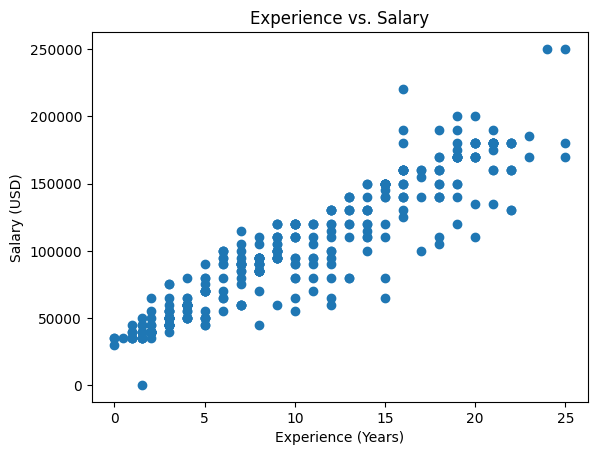

In [4]:
# მონაცემების ვიზუალიზაცია, როგორაა ხელფასი გამოცდილებაზე დამოკიდებული 
plt.scatter(df_salary["Years of Experience"], df_salary["Salary"])
plt.xlabel("Experience (Years)")
plt.ylabel("Salary (USD)")
plt.title("Experience vs. Salary");

In [5]:
# მონაცემების მომზადება მოდელის გასაწვრთნელად
X = df_salary[["Years of Experience"]]
y = df_salary["Salary"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [6]:
# Feature Scaling / Standardization
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [7]:
# წრფივი რეგრესიის მოდელი
model = LinearRegression()
model.fit(X_train_scaled, y_train) # მოდელის გაწვრთნა training data-ის გამოყენებით

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [8]:
# ხელფასის პროგნოზირება testing data-ის გამოყენებით
y_pred = model.predict(X_test_scaled)

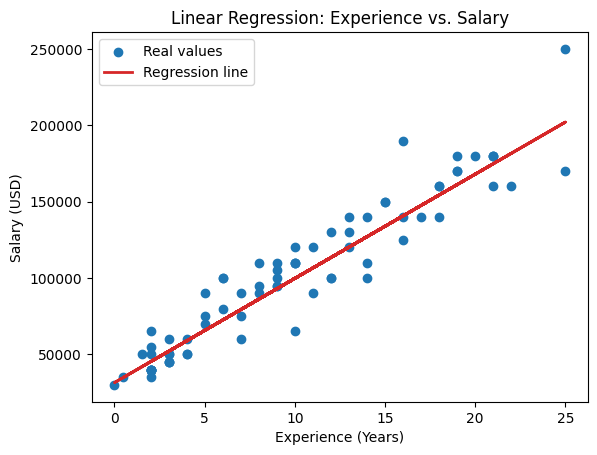

In [9]:
# რეგრესიის ხაზის ვიზუალიზაცია
plt.scatter(X_test, y_test, label="Real values")
plt.plot(X_test, y_pred, color="C3", linewidth=2, label="Regression line")
plt.xlabel("Experience (Years)")
plt.ylabel("Salary (USD)")
plt.title("Linear Regression: Experience vs. Salary")
plt.legend();

In [13]:
# მოდელის კოეფიციენტები y = a * x + b
print(f"Slope (a): {model.coef_[0]:.2f}") # ხაზის დახრილობა
print(f"Intercept (b): {model.intercept_:.2f}") # გადაკვეთის წერტილი

Slope (a): 44386.34
Intercept (b): 100101.85


In [14]:
slope_original = model.coef_[0] / scaler.scale_[0]
intercept_original = model.intercept_ - slope_original * scaler.mean_[0]

print(f"Slope in original scale: {slope_original:.2f}")
print(f"Intercept in original scale: {intercept_original:.2f}")

Slope in original scale: 6822.59
Intercept in original scale: 31521.08


Slope in original scale: გამოცდილების 1 წლით ზრდისას,
ხელფასი საშუალოდ slope_original USD-ით იზრდება.

Intercept in original scale: 0 წლის გამოცდილების შემთხვევაში,
მოდელი პროგნოზირებს დაახლოებით intercept_original USD ხელფასს.

In [12]:
# ხელფასის პროგნოზი 5, 10 და 15 წლის გამოცდილების მიხედვით
future_experience = np.array([[5], [10], [15]])

# იგივე scaler, რომელიც X_train-ზე დავატრენინგეთ
future_experience_scaled = scaler.transform(future_experience)

# პროგნოზი უკვე დასკეილებულ მონაცემებზე
future_salary = model.predict(future_experience_scaled)

for exp, salary in zip(future_experience.flatten(), future_salary):
    print(
        f"Prediction: With {exp} years of experience, "
        f"the salary is approximately {salary:.2f} USD."
    )

Prediction: With 5 years of experience, the salary is approximately 65634.03 USD.
Prediction: With 10 years of experience, the salary is approximately 99746.98 USD.
Prediction: With 15 years of experience, the salary is approximately 133859.93 USD.


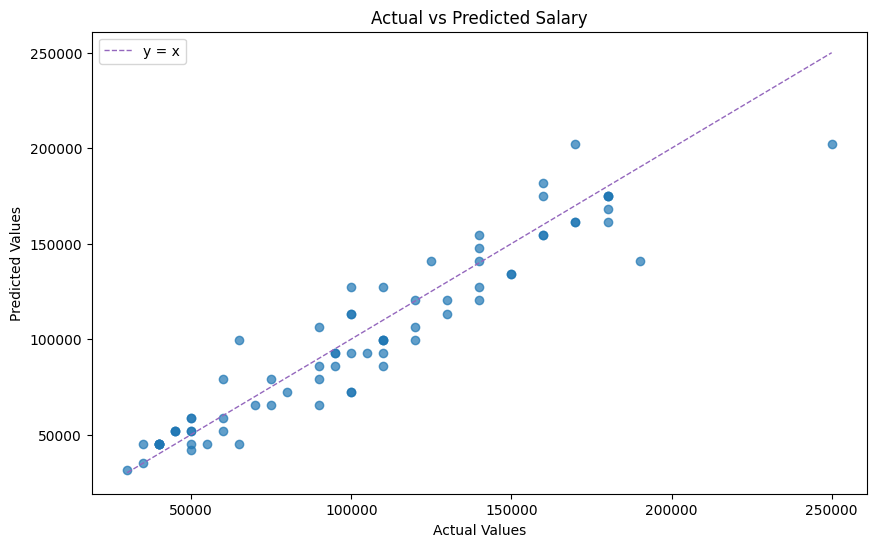

In [15]:
# პროგნოზისა და ნამდვილი მონაცემების შედარება
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(y_test, y_pred, alpha=0.7)
ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "k--", lw=1, color="C4", label="y = x")
ax.set_title("Actual vs Predicted Salary")
ax.set_xlabel("Actual Values")
ax.set_ylabel("Predicted Values")
ax.legend();

##### **მოდელის შეფასება**

წრფივი რეგრესიის მოდელის ხარისხის გასაზომად ხშირად ვიყენებთ **MAE**, **MSE**, **RMSE** და **R² Score** მეტრიკებს.  
ეს მაჩვენებლები გვეხმარება, გავიგოთ, რამდენად ზუსტია მოდელის პროგნოზი.

**Mean Absolute Error (MAE) - საშუალო აბსოლუტური შეცდომა** ზომავს, საშუალოდ რამდენით ცდება მოდელის პროგნოზი რეალურ მნიშვნელობას.  
ეს არის სხვაობების აბსოლუტური მნიშვნელობების საშუალო.

ფორმულა:

$MAE = \frac{1}{n} \sum_{i=1}^{n} | y_i - \hat{y_i} |$ 

სადაც:
- $y_i$ – რეალური მნიშვნელობები
- $\hat{y_i}$ – პროგნოზირებული მნიშვნელობები
- $n$ – მონაცემთა რაოდენობა

* დაბალი MAE → უკეთესი მოდელი, ნაკლები შეცდომა,
* დიდი MAE ნიშნავს, რომ მოდელის პროგნოზი შორსაა რეალური მნიშვნელობებისგან.

**Mean Squared Error (MSE) - საშუალო კვადრატული შეცდომა** ზომავს საშუალო კვადრატული სხვაობას რეალურ და პროგნოზირებულ მნიშვნელობებს შორის.  

ფორმულა:

$MSE = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y_i})^2$

- MSE ყოველთვის არანულოვანი და არანეგატიურია.
- დაბალი MSE → უკეთესი პროგნოზი.
- დიდი შეცდომები უფრო მეტ გავლენას ახდენენ MSE-ზე, რადგან კვადრატულია.

**Root Mean Squared Error (RMSE) – ფესვიანი საშუალო კვადრატული შეცდომა**  გვიჩვენებს, რამდენად შორდება მოდელის პროგნოზები რეალურ მნიშვნელობებს საშუალოდ.  
იგი MSE-ს კვადრატული ფესვია, რაც ნიშნავს, რომ ამცირებს კვადრატული შეცდომის ერთეულების ეფექტს და უფრო ინტერპრეტირებადს ხდის შედეგებს.

ფორმულა:

$RMSE = \sqrt{\frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y_i})^2}$

- დაბალი RMSE → მოდელი უფრო ზუსტია (შეცდომები მცირეა).  
- მაღალი RMSE → მოდელი ცუდად მუშაობს (დიდი შეცდომები). 
- RMSE-ს ერთეული იგივეა, რაც პროგნოზირებული ცვლადის (მაგალითად, თუ ხელფასს ვპროგნოზირებთ დოლარში, RMSE ერთეულიც იქნება დოლარში).  
- შედარებისთვის, თუ MAE და RMSE მნიშვნელოვნად განსხვავდება, ეს ნიშნავს, რომ მოდელს აქვს დიდი ცალკეული შეცდომები, რომლებიც მნიშვნელოვან გავლენას ახდენენ საშუალოზე.

თუ RMSE ≈ MAE, ნიშნავს, რომ მოდელის შეცდომები დიდად არ განსხვავდება ერთმანეთისგან.  
თუ RMSE მნიშვნელოვნად დიდია MAE-ზე, ეს მიუთითებს იმაზე, რომ მოდელი ზოგიერთ დიდ შეცდომას უშვებს (მაგალითად, ერთ ან რამდენიმე მონაცემზე).

---
| მეტრიკა  | უპირატესობები | როდის გამოვიყენოთ? |
|-------------|----------------|----------------|
| MAE    | ინტერპრეტაცია მარტივია, არაა სენსიტიური დიდ შეცდომებზე | თუ ყველა შეცდომა ერთნაირად მნიშვნელოვანია |
| MSE    | დიდ შეცდომებს უფრო მეტ მნიშვნელობას ანიჭებს | როცა დიდი შეცდომების აღმოჩენა გვსურს |
| RMSE   | აქვს იგივე ერთეული, როგორც დამოკიდებული ცვლადი, ამიტომ ინტერპრეტაცია მარტივია | როცა გვინდა პრაქტიკული ინტერპრეტაცია |

---

**R² Score (Determination Coefficient)** გვიჩვენებს, რამდენად კარგად ხსნის მოდელი მონაცემთა ვარიაციას.

ფორმულა:

$R^2 = 1 - \frac{\sum (y_i - \hat{y_i})^2}{\sum (y_i - \bar{y})^2}$

სადაც:
- $\bar{y}$ – რეალური მონაცემების საშუალო.

შეფასება:
- $R^2 = 1$ → იდეალური მოდელი (პროგნოზი 100%-ით ზუსტია).
- $R^2 = 0$ → მოდელი არ ხსნის მონაცემთა ვარიაციას (ისევე მუშაობს, როგორც საშუალოს გამოყენება).
- $R^2 < 0$ → მოდელი უარესია, ვიდრე უბრალოდ მონაცემების საშუალოს გამოყენება.

**თუ R² მაღალია და MAE/MSE დაბალია, ეს ნიშნავს, რომ მოდელი კარგად პროგნოზირებს!**

,Salary
mean,102466.666667
std,49294.847418
min,30000.000000
50%,100000.000000
max,250000.000000


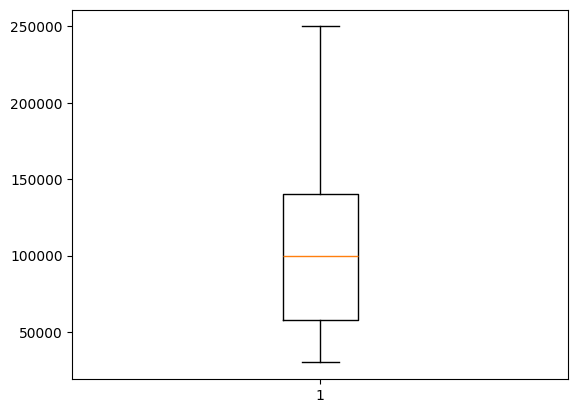

In [16]:
# ხელფასების დიაპაზონი
plt.boxplot(y_test)
pd.DataFrame(y_test.describe().loc[['mean', 'std', 'min', '50%', 'max']])

In [17]:
# მეტრიკებით პროგნოზის შეფასება, თუ რამდენად შორსაა ის ნამდვილი მნიშვნელობებისაგან
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.2f}") # ერთეული - $
print(f"Mean Squared Error (MSE): {mse:.2f}") # ერთეული - $²
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}") # ერთეული - $
print(f"R² Score: {r2:.2f}")

Mean Absolute Error (MAE): 12094.17
Mean Squared Error (MSE): 241834883.90
Root Mean Squared Error (RMSE): 15551.04
R² Score: 0.90


In [19]:
# მოდელს აქვს ასევე ფუქნცია R² Score-ის დასათვლელად
r2 = model.score(X_test_scaled, y_test)
print(f"R² Score: {r2:.2f}")

R² Score: 0.90


$R^2 = 0.90$, ეს ნიშნავს, რომ მოდელი ხსნის მონაცემთა ვარიაციის 90%-ს. ანუ, მოდელის პროგნოზები ძალიან ახლოსაა რეალურ მონაცემებთან.
მონაცემთა 90%-ს სიზუსტით აღვწერთ, ხოლო 10% რჩება აუხსნელი.

$R^2$ არ უნდა იყოს ერთადერთი კრიტერიუმი – ასევე უნდა შევამოწმოთ MSE და MAE.

$y_{\text{test}} - y_{\text{pred}}$– წარმოადგენს შეცდომებს ან ნარჩენებს (residuals), ანუ რეალური და პროგნოზირებული მნიშვნელობების სხვაობას.
ჰისტოგრამა გვიჩვენებს, როგორ ნაწილდება ეს შეცდომები:

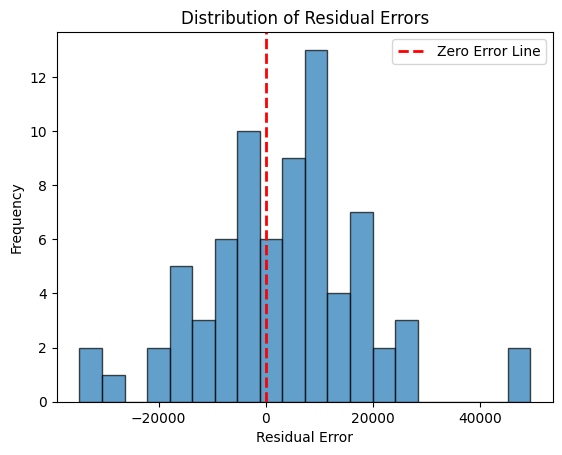

In [20]:
# დაითვალე residual errors
errors = y_test - y_pred

# სხვაობის ჰისტოგრამა
plt.hist(errors, bins=20, edgecolor='black', alpha=0.7)
plt.xlabel("Residual Error")
plt.ylabel("Frequency")
plt.title("Distribution of Residual Errors")
plt.axvline(x=0, color='red', linestyle='dashed', linewidth=2, label="Zero Error Line")
plt.legend()
plt.show()

რას უნდა დავაკვირდეთ ჰისტოგრამაზე?
1. თუ შეცდომები ნორმალურად (გაუსის განაწილებით) ნაწილდება → რეგრესიული მოდელი კარგად მუშაობს.
2. თუ შეცდომები ასიმეტრიულია → შეიძლება მონაცემებში იყოს ბაიასები ან მოდელს კარგად არ ფუნქციონირებს. 
3. თუ შეცდომები ძალიან ფართოდაა განაწილებული → პროგნოზები ძალიან არაზუსტია და მოდელს სჭირდება გაუმჯობესება.
4. თუ შეცდომები ცენტრირებულია ნულთან → მოდელი ზუსტია და შეცდომები მცირეა.

- იდეალურ შემთხვევაში, ჰისტოგრამა უნდა იყოს გაუსისებური (ნორმალური განაწილება) და ცენტრში (0-ზე) სიმეტრიული.  
- თუ ჰისტოგრამა ასიმეტრიულია, შესაძლებელია:
  - მოდელს აკლია მნიშვნელოვანი ცვლადები
  - მონაცემები არ არის კარგად გაწმენდილი
  - გამოყენებული რეგრესიული მეთოდი არ არის საუკეთესო არჩევანი 

#### Multiple linear regression

In [21]:
# გამოვიყენოთ ყველა სვეტი ხელფასის პროგნოზისათვის
df_salary = df[["Age", "Gender", "Education Level", "Years of Experience", "Salary"]].dropna() 

In [22]:
# Preprocessing: 

# გარდავქმნათ str სვეტები რიცხვოვან მონაცემებთან categorical -> numerical
encoder = LabelEncoder()
df_salary["Gender"] = encoder.fit_transform(df_salary["Gender"])

enc = OrdinalEncoder(categories=[["Bachelor's", "Master's", "PhD"]], handle_unknown="use_encoded_value", unknown_value=-1)
df_salary["Education Level"] = enc.fit_transform(df_salary[["Education Level"]]).astype(int)

In [23]:
# მონაცემების მომზადება მოდელის გასაწვრთნელად
X = df_salary.drop(columns="Salary")
y = df_salary["Salary"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [24]:
# Feature Scaling / Standardization
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [25]:
# წრფივი რეგრესიის მოდელი
model = LinearRegression()
model.fit(X_train_scaled, y_train) # მოდელის გაწვრთნა training data-ის გამოყენებით

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [28]:
# ხელფასის პროგნოზირება testing data-ის გამოყენებით
y_pred = model.predict(X_test_scaled)

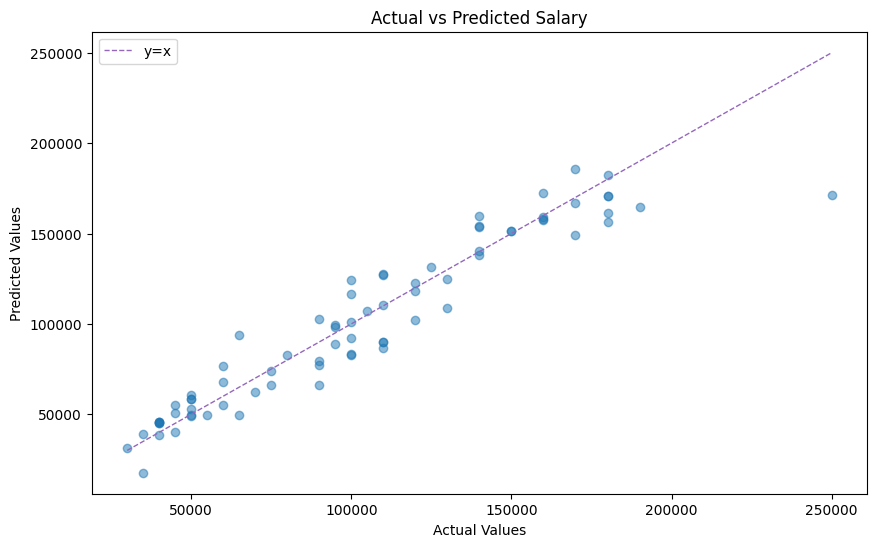

In [29]:
# პროგნოზისა და ნამდვილი მონაცემების შედარება
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(y_test, y_pred, alpha=0.5)
ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "k--", lw=1, color="C4", label="y=x")
ax.set_title("Actual vs Predicted Salary")
ax.set_xlabel("Actual Values")
ax.set_ylabel("Predicted Values")
ax.legend();

In [33]:
# კოეფიციენტების გადაყვანა ორიგინალურ მასშტაბში
coef_original = model.coef_ / scaler.scale_

# intercept-ის გადაყვანა ორიგინალურ მასშტაბში
intercept_original = model.intercept_ - np.sum(coef_original * scaler.mean_)

# მოდელის კოეფიციენტები სკალირებულ მასშტაბში
print("Scaled coefficients:")
[print(f"a_{n+1} = {c:.2f}") for n, c in enumerate(model.coef_)]
print(f"a_0 = {model.intercept_:.2f}")

print("\nOriginal scale coefficients:")

# კოეფიციენტები ორიგინალურ მასშტაბში y = a_1 x_1 + a_2 x_2 + a_3 x_3 + a_4 x_4 + a_0
coef_original = model.coef_ / scaler.scale_

# intercept ორიგინალურ მასშტაბში
intercept_original = model.intercept_ - np.sum(coef_original * scaler.mean_)

[print(f"a_{n+1} = {c:.2f}") for n, c in enumerate(coef_original)]
print(f"a_0 = {intercept_original:.2f}")

Scaled coefficients:
a_1 = 24616.09
a_2 = 3802.94
a_3 = 10728.96
a_4 = 13648.16
a_0 = 100101.85

Original scale coefficients:
a_1 = 3500.98
a_2 = 7606.57
a_3 = 15003.86
a_4 = 2097.85
a_0 = -63895.57


წრფივ რეგრესიაში მახასიათებლის მნიშვნელობა (feature importance) კოეფიციენტების აბსოლუტური მნიშვნელობაა.  

- უფრო დიდი კოეფიციენტები → უფრო დიდი გავლენა აქვს დამოკიდებულ ცვლადზე.
- სტატისტიკური მნიშვნელობის შესამოწმებლად გამოიყენე `statsmodels` და p-values.

In [35]:
# რამდენად მნიშვნელოვანია მახასიათებლები
importance = np.abs(model.coef_)

# feature names ავიღოთ საწყისი X DataFrame-იდან
feature_names = X.columns

# Create DataFrame for better visualization
importance_df = pd.DataFrame({"Feature": feature_names, "Importance": importance})
importance_df = importance_df.sort_values(by="Importance", ascending=False)
importance_df

,Feature,Importance
0,Age,24616.094533
3,Years of Experience,13648.159540
2,Education Level,10728.963626
1,Gender,3802.940602


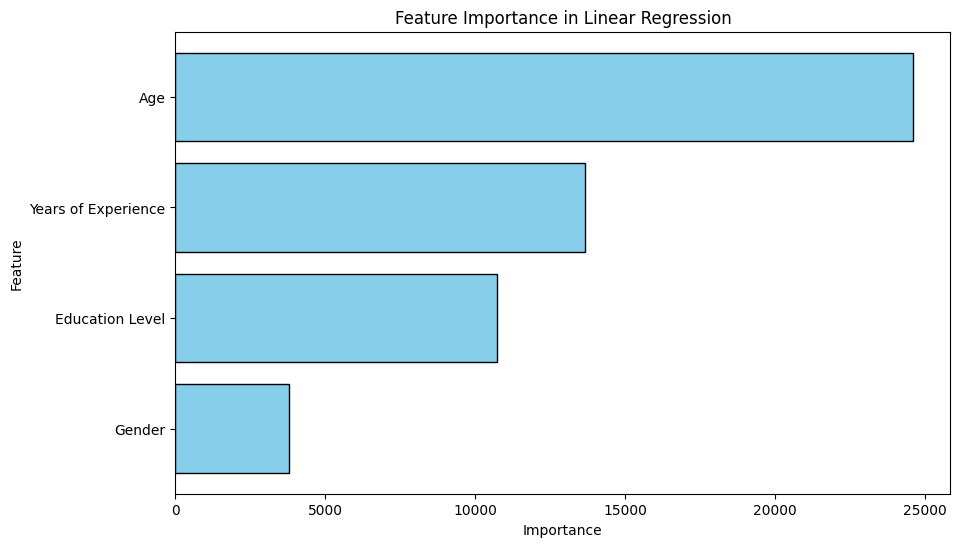

In [36]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(importance_df["Feature"], importance_df["Importance"], color="skyblue", edgecolor="black")
ax.set_xlabel("Importance")
ax.set_ylabel("Feature")
ax.set_title("Feature Importance in Linear Regression")
plt.gca().invert_yaxis()  # Invert y-axis to show the most important feature on top

In [37]:
# მეტრიკებით პროგნოზის შეფასება, თუ რამდენად შორსაა ის ნამდვილი მნიშვნელობებისაგან
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.2f}") # ერთეული - $
print(f"Mean Squared Error (MSE): {mse:.2f}") # ერთეული - $²
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}") # ერთეული - $
print(f"R² Score: {r2:.2f}")

Mean Absolute Error (MAE): 10613.91
Mean Squared Error (MSE): 232595028.53
Root Mean Squared Error (RMSE): 15251.07
R² Score: 0.90


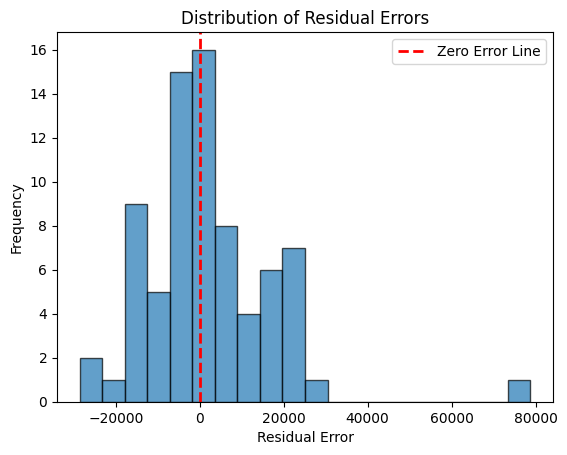

In [38]:
# დაითვალე residual errors
errors = y_test - y_pred

# სხვაობის ჰისტოგრამა
plt.hist(errors, bins=20, edgecolor='black', alpha=0.7)
plt.xlabel("Residual Error")
plt.ylabel("Frequency")
plt.title("Distribution of Residual Errors")
plt.axvline(x=0, color='red', linestyle='dashed', linewidth=2, label="Zero Error Line")
plt.legend()
plt.show()

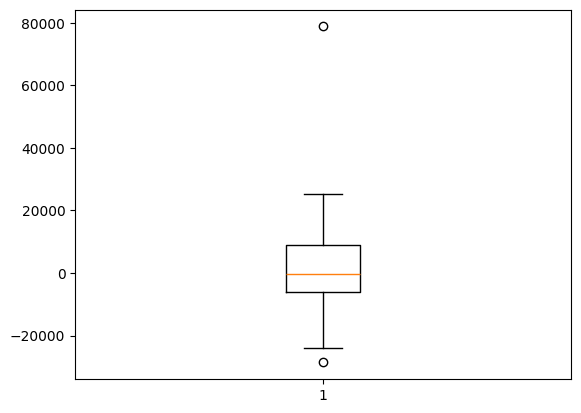

In [39]:
plt.boxplot(errors);

In [40]:
# მოვძებნოთ აუთლაიერი ინდექსის საშუალებით
df_salary.iloc[errors.sort_values().index[-1]]

Age                        50.0
Gender                      1.0
Education Level             0.0
Years of Experience        25.0
Salary                 250000.0
Name: 30, dtype: float64

In [41]:
# შევამოწმოთ რამდენ ადამიანს აქვს იგივე ხელფასი
df_salary[df_salary["Salary"] == 250000]

,Age,Gender,Education Level,Years of Experience,Salary
30,50.0,1,0,25.0,250000.0
83,52.0,1,2,24.0,250000.0


In [42]:
# შევამოწმოთ რამდენ ადამიანს აქვს იგივე გამოცდილება
df_salary[df_salary["Years of Experience"] == 25]

,Age,Gender,Education Level,Years of Experience,Salary
30,50.0,1,0,25.0,250000.0
93,52.0,0,1,25.0,170000.0
121,53.0,1,1,25.0,180000.0


In [43]:
# შევამოწმოთ რამდენი ადამიანია იმავე ასაკის
df_salary[df_salary["Age"] == 50]

,Age,Gender,Education Level,Years of Experience,Salary
30,50.0,1,0,25.0,250000.0
76,50.0,0,0,22.0,160000.0
112,50.0,0,0,22.0,130000.0
130,50.0,0,1,21.0,160000.0
170,50.0,0,1,20.0,180000.0
188,50.0,0,2,22.0,180000.0
217,50.0,0,2,22.0,180000.0
258,50.0,0,2,22.0,180000.0


##### **მოდელის შეჯამება**

In [44]:
# Fit the model using statsmodels
# OLS (Ordinary Least Squares, ჩვეულებრივი უმცირესი კვადრატების მეთოდი)
features = X.columns
X = sm.add_constant(X)
model = sm.OLS(y, X).fit()

model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Salary   R-squared:                       0.900
Model:                            OLS   Adj. R-squared:                  0.899
Method:                 Least Squares   F-statistic:                     831.5
Date:                Mon, 04 May 2026   Prob (F-statistic):          8.24e-183
Time:                        11:38:39   Log-Likelihood:                -4121.0
No. Observations:                 373   AIC:                             8252.
Df Residuals:                     368   BIC:                             8272.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
=======================================================================================
                          coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------
const               -4.455e+04   1.52e+04     -2.934      0.004   -7.44e+04   -1.47e+04
Age                  2745.7510    559.071      4.911      0.000    1646.376    3845.126
Gender               8397.5975   1600.786      5.246      0.000    5249.762    1.15e+04
Education Level      1.343e+04   1369.311      9.806      0.000    1.07e+04    1.61e+04
Years of Experience  3068.8099    617.992      4.966      0.000    1853.571    4284.049
==============================================================================
Omnibus:                       23.043   Durbin-Watson:                   1.894
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               68.119
Skew:                           0.153   Prob(JB):                     1.61e-15
Kurtosis:                       5.071   Cond. No.                         762.
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

* R² = 0.900 ნიშნავს, რომ მოდელი *Salary*-ის დისპერსიის 90%-ს ხსნის.
* Adjusted R² = 0.899 
  $$
  \text{Adj }R^2 = 1 - (1-R^2)\frac{n-1}{n-p-1},
  $$
  სადაც $p$ არის მახასიათებლების რაოდენობა.

* თუ Adjusted R² მეტად დაბალია R²-თან შედარებით → შესაძლოა overfitting გვაქვს.
* თუ ისინი თითქმის ტოლია → მოდელის სირთულე აზრიანია.

P-values < 0.05 ნიშნავს რომ მახასიათებელი მოდელისათვის სტატისტიკურად მნიშვნელოვანია

In [45]:
# მოკლე summary
df_summary = pd.DataFrame({
    "Feature": model.params.index, 
    "Coefficient": model.params.values.round(3),  
    "P-Value": model.pvalues.values.round(3) 
})

# დავალაგოთ P-Value-ის მიხედვით
df_summary = df_summary.sort_values(by="Coefficient", ascending=False)
df_summary = df_summary[df_summary.Feature.isin(features)]
df_summary

,Feature,Coefficient,P-Value
3,Education Level,13426.873,0.0
2,Gender,8397.597,0.0
4,Years of Experience,3068.810,0.0
1,Age,2745.751,0.0


ყველაზე მნიშვნელოვანი მახასიათებლებია:  

- განათლების დონე (Education Level)
- სქესი (Gender)
- გამოცდილების წლები (Years of Experience)
- ასაკი (Age)

განსხვავება `statsmodels` OLS და `scikit-learn` LinearRegression შორის:

|  | statsmodels OLS | scikit-learn LinearRegression |
|---|---------------------|---------------------------------|
| მიზანი | სტატისტიკური ანალიზი | მანქანური სწავლება (Machine Learning) |
| p-values & Statistical Tests | აქვს | არ აქვს |
| Confidence Intervals | აქვს | არ აქვს |
| მოდელის ანალიზი (`summary()`) | დეტალური ანალიზი | მხოლოდ R² და კოეფიციენტები |
| პროგნოზი (`predict()`) | შესაძლებელია | შესაძლებელია |
| სიჩქარე | შედარებით ნელია | უფრო სწრაფია |


✔ თუ გჭირდება დეტალური სტატისტიკური ანალიზი → გამოიყენე `statsmodels`  
✔ თუ გჭირდება სწრაფი მანქანური სწავლება და პროგნოზი → გამოიყენე `scikit-learn`  

#### Multicollinearity

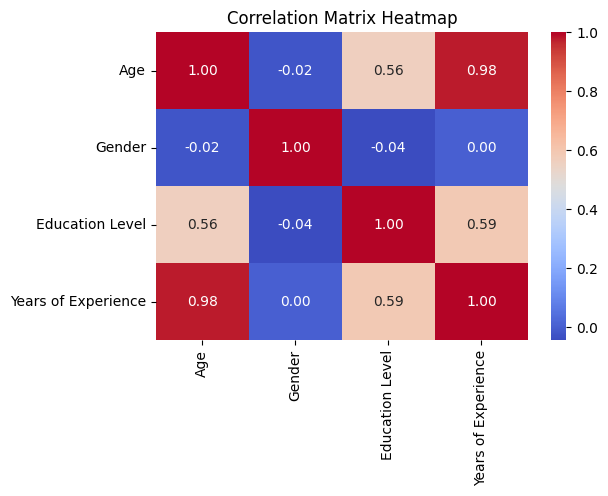

In [46]:
# კორელაციის მატრიცა
corr_matrix = df_salary.drop(columns=["Salary"], axis=1).select_dtypes(include="number").corr()
plt.figure(figsize=(6, 4))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix Heatmap")
plt.show()

ასაკის, სამუშაო გამოცდილებისა და ხელფასის შორის ძალიან მაღალი კორელაციის კოეფიციენტები მიუთითებენ, რომ ორივე მახასიათებლის - ასაკისა და სამუშაო გამოცდილების - ერთდროულად ჩართვამ რეგრესიულ მოდელში შეიძლება გამოიწვიოს მულტიკოლინეარობის პრობლემები.

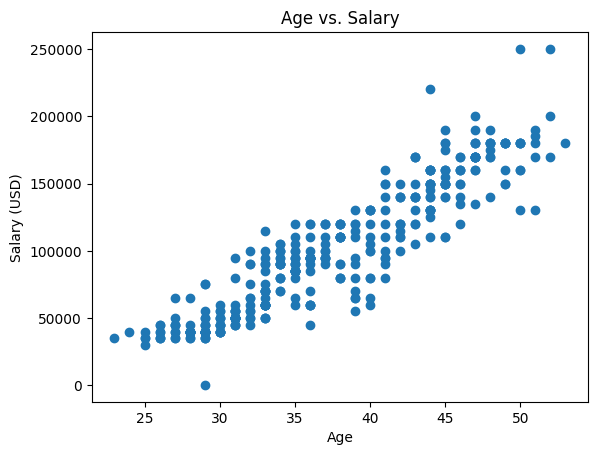

In [47]:
# მონაცემების ვიზუალიზაცია, როგორაა ხელფასი ასაკზე დამოკიდებული 
plt.scatter(df_salary["Age"], df_salary["Salary"])
plt.xlabel("Age")
plt.ylabel("Salary (USD)")
plt.title("Age vs. Salary");

მულტიკოლინეარობა პრობლემატიურია, ართულებს მოდელის ინტერპრეტაციას, ამცირებს პროგნოზის სიზუსტეს და შესაძლოა გამოიწვიოს მოდელის არასტაბილურობა.
მაღალი კორელაციის გამო, მონაცემებში მცირე ცვლილებამ შეიძლება გამოიწვიოს დიდი ცვლილებები კოეფიციენტებში. 
რთულია ცვლადების ინდივიდუალური გავლენის გასხვავება. მაგ., ასაკი და გამოცდილება ერთდროულად ახდენს გავლენას ხელფასზე, რის გამოც რთულია განსაზღვრა რომელია უფრო მნიშვნელოვანი.
შესაძლოა გამოიწვიოს Overfitting.

In [48]:
# მონაცემების მომზადება მოდელის გასაწვრთნელად, არ ვითვალისწინებთ "Age" სვეტს
X = df_salary.drop(columns=["Age", "Salary"])
y = df_salary["Salary"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [50]:
# Feature Scaling / Standardization
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [51]:
# წრფივი რეგრესიის მოდელი
model = LinearRegression()
model.fit(X_train_scaled, y_train) # მოდელის გაწვრთნა training data-ის გამოყენებით

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [52]:
# ხელფასის პროგნოზირება testing data-ის გამოყენებით
y_pred = model.predict(X_test_scaled)

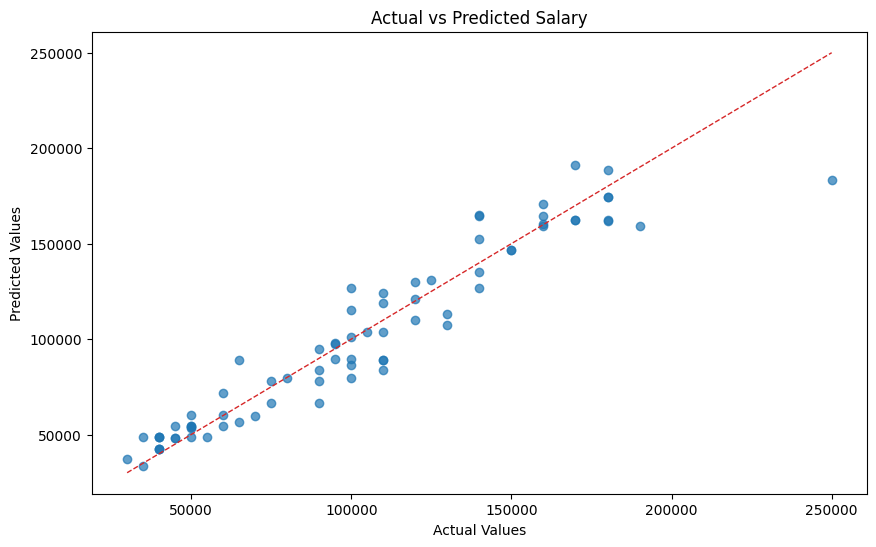

In [53]:
# პროგნოზისა და ნამდვილი მონაცემების შედარება
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(y_test, y_pred, alpha=0.7)
ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "k--", lw=1, color="C3")
ax.set_title("Actual vs Predicted Salary")
ax.set_xlabel("Actual Values")
ax.set_ylabel("Predicted Values");

In [54]:
# რამდენად მნიშვნელოვანია მახასიათებლები (feature importance)
importance = np.abs(model.coef_)
feature_names = X.columns

# Create DataFrame for better visualization
importance_df = pd.DataFrame({"Feature": feature_names, "Importance": importance})
importance_df = importance_df.sort_values(by="Importance", ascending=False)
importance_df

,Feature,Importance
2,Years of Experience,38140.969964
1,Education Level,10132.467786
0,Gender,3268.773241


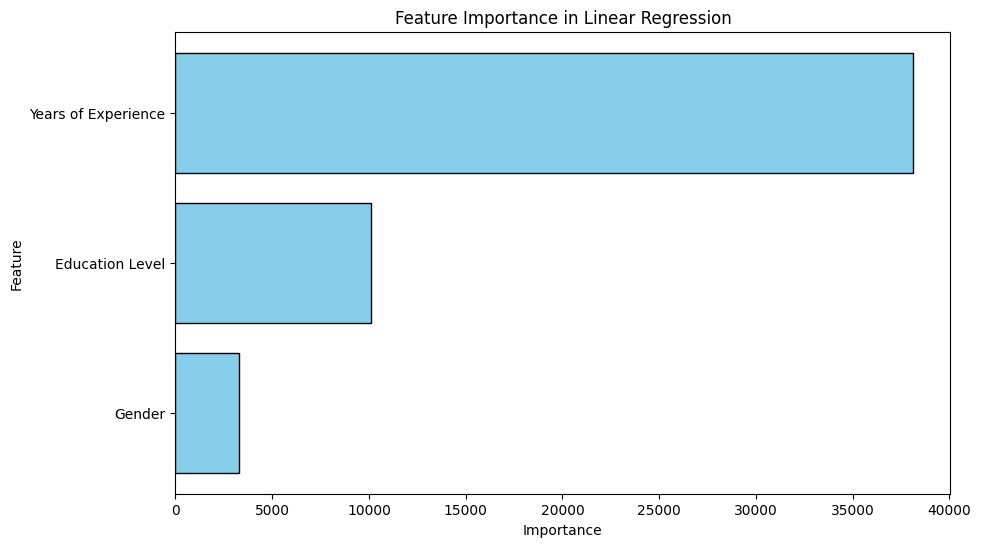

In [55]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(importance_df["Feature"], importance_df["Importance"], color="skyblue", edgecolor="black")
ax.set_xlabel("Importance")
ax.set_ylabel("Feature")
ax.set_title("Feature Importance in Linear Regression")
plt.gca().invert_yaxis()  # Invert y-axis to show the most important feature on top

In [56]:
# მეტრიკებით პროგნოზის შეფასება, თუ რამდენად შორსაა ის ნამდვილი მნიშვნელობებისაგან
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.2f}") # ერთეული - $
print(f"Mean Squared Error (MSE): {mse:.2f}") # ერთეული - $²
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}") # ერთეული - $
print(f"R² Score: {r2:.2f}")

Mean Absolute Error (MAE): 10362.67
Mean Squared Error (MSE): 207876432.19
Root Mean Squared Error (RMSE): 14417.92
R² Score: 0.91


ევალუაციის მეტრიკებიდან ჩანს რომ მოდელის პერფორმანსი გაუმჯობესდა.

#### Medical Cost Personal Datasets: დაზღვევის ხარჯების (charges) პროგნოზირება

In [57]:
# მონაცემების წაკითხვა csv ფაილიდან
df_insurance = pd.read_csv("../../datasets/medical_cost/insurance.csv")
df_insurance.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [61]:
# Preprocessing: 

# გარდავქმნათ str სვეტები რიცხვოვან მონაცემებთან categorical -> numerical
encoder = LabelEncoder()
df_insurance["sex"] = encoder.fit_transform(df_insurance["sex"])
df_insurance["smoker"] = encoder.fit_transform(df_insurance["smoker"])

encoder = OneHotEncoder(sparse_output=False)
region_encoded = encoder.fit_transform(df_insurance[["region"]])

df_region = pd.DataFrame(region_encoded, columns=encoder.get_feature_names_out(["region"]))
df_insurance = pd.concat([df_insurance.drop(columns="region", axis=1), df_region], axis=1)

In [63]:
# გამოვყოთ მახასიათებლები (features - X) და სამიზნე სვეტი (target variable - y), რომლის პროგნოზირებაც უნდა მოხდეს 
X = df_insurance.drop(columns=["charges"])
y = df_insurance["charges"]

# მონაცემები დავყოთ, training sets - მონაცემების ის ნაწილი რომელიც გადაეცემა შესასწავლად და testing sets - სატესტო მონაცემები 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42) # (80% training, 20% testing)

In [64]:
# Feature Scaling / Standardization
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [65]:
# წრფივი რეგრესიის მოდელი
model = LinearRegression()
model.fit(X_train_scaled, y_train) # მოდელის გაწვრთნა training data-ის გამოყენებით

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [66]:
# ხელფასის პროგნოზირება testing data-ის გამოყენებით
y_pred = model.predict(X_test_scaled)

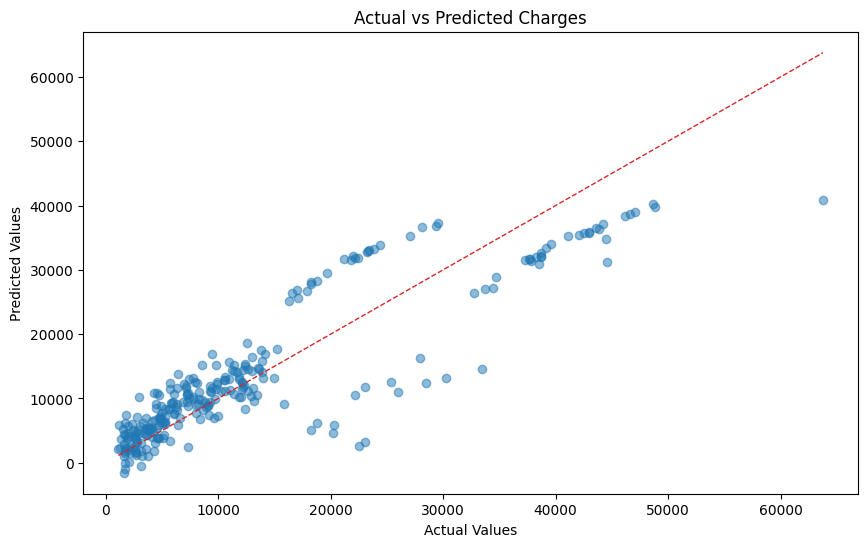

In [67]:
# პროგნოზისა და ნამდვილი მონაცემების შედარება
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(y_test, y_pred, alpha=0.5)
ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "k--", lw=1, color="C3")
ax.set_title("Actual vs Predicted Charges")
ax.set_xlabel("Actual Values")
ax.set_ylabel("Predicted Values");

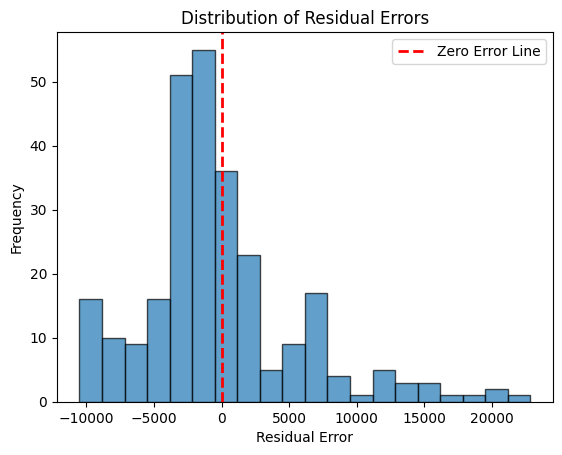

In [68]:
# დაითვალე residual errors
errors = y_test - y_pred

# სხვაობის ჰისტოგრამა
plt.hist(errors, bins=20, edgecolor='black', alpha=0.7)
plt.xlabel("Residual Error")
plt.ylabel("Frequency")
plt.title("Distribution of Residual Errors")
plt.axvline(x=0, color='red', linestyle='dashed', linewidth=2, label="Zero Error Line")
plt.legend()
plt.show()

In [69]:
# მეტრიკებით პროგნოზის შეფასება, თუ რამდენად შორსაა ის ნამდვილი მნიშვნელობებისაგან
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.2f}") # 
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}") # 
print(f"R² Score: {r2:.2f}")

Mean Absolute Error (MAE): 4181.19
Root Mean Squared Error (RMSE): 5796.28
R² Score: 0.78


In [70]:
# მოდელის კოეფიციენტები y = a_1 x_1 + a_2 x_2 + a_3 x_3 + a_4 x_4 + a_5 x_5 + a_6 x_6 + a_0
[print(f"a_{n+1} = {c:.2f}") for n, c in enumerate(model.coef_)]
print(f"a_0 = {model.intercept_:.2f}")

a_1 = 3614.98
a_2 = -9.29
a_3 = 2036.23
a_4 = 516.89
a_5 = 9558.48
a_6 = 199.70
a_7 = 38.73
a_8 = -86.62
a_9 = -150.17
a_0 = 13346.09


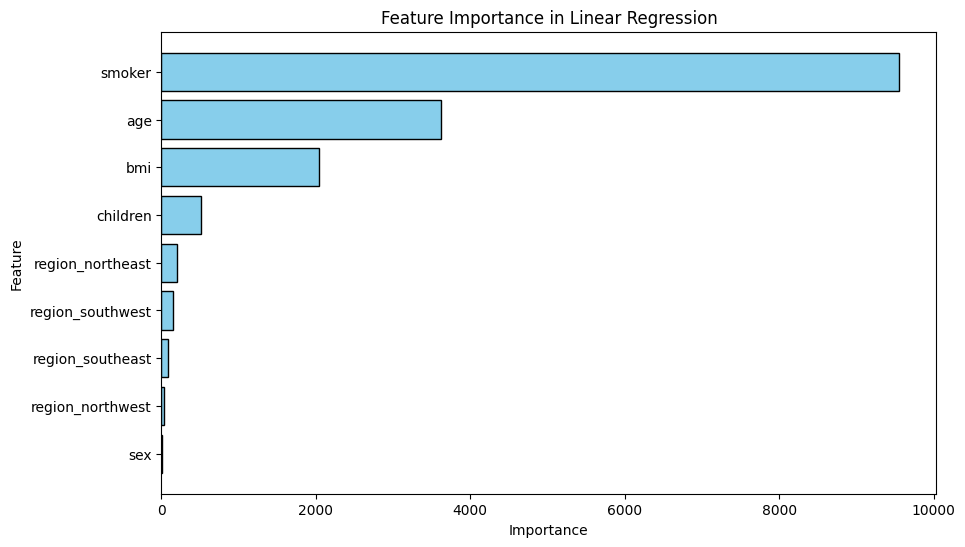

In [72]:
# რამდენად მნიშვნელოვანია მახასიათებლები (feature importance)
importance = np.abs(model.coef_)
feature_names = X.columns

# Create DataFrame for better visualization
importance_df = pd.DataFrame({"Feature": feature_names, "Importance": importance})
importance_df = importance_df.sort_values(by="Importance", ascending=False)

plt.figure(figsize=(10, 6))
plt.barh(importance_df["Feature"], importance_df["Importance"], color="skyblue", edgecolor="black")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importance in Linear Regression")
plt.gca().invert_yaxis()  # Invert y-axis to show the most important feature on top
plt.show()